
# Policy & Financial Performance Analysis

## Objective

Evaluate insurance portfolio performance using policy
distribution, annual premiums, coverage amounts, and
financial indicators.

### Key Analysis Areas

- Policy portfolio composition
- Annual premium distribution and revenue potential
- Coverage exposure across policy types
- Premium-to-coverage relationships
- Policy status and financial performance
- Business insights and recommendations

### Tools

Python | Pandas | NumPy | Matplotlib | Seaborn | MySQL


In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, URL
from getpass import getpass

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

# Connect to MySQL database

db_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("Enter MySQL Password: "),
    host="localhost",
    port=3306,
    database="insurance_claims_analytics"
)

engine = create_engine(db_url)

# Verify database connection
with engine.connect() as connection:
    print("MySQL database connected successfully.")


MySQL database connected successfully.


In [3]:

# Load required tables from MySQL

policies = pd.read_sql("SELECT * FROM policies", engine)
claims = pd.read_sql("SELECT * FROM claims", engine)
customers = pd.read_sql("SELECT * FROM customers", engine)
payments = pd.read_sql("SELECT * FROM payments", engine)

# Verify table dimensions
print("Policies:", policies.shape)
print("Claims:", claims.shape)
print("Customers:", customers.shape)
print("Payments:", payments.shape)


Policies: (15000, 8)
Claims: (25000, 7)
Customers: (10000, 6)
Payments: (15541, 5)


In [4]:

# Verify structure and missing values

for name, df in {
    "Policies": policies,
    "Claims": claims,
    "Customers": customers,
    "Payments": payments
}.items():
    print(f"\n{name}")
    print("Columns:", df.columns.tolist())
    print("Missing Values:", df.isnull().sum().sum())



Policies
Columns: ['Policy_ID', 'Customer_ID', 'Policy_Type', 'Start_Date', 'End_Date', 'Annual_Premium', 'Coverage_Amount', 'Policy_Status']
Missing Values: 0

Claims
Columns: ['Claim_ID', 'Policy_ID', 'Claim_Date', 'Claim_Amount', 'Claim_Status', 'Fraud_Flag', 'Claim_Type']
Missing Values: 0

Customers
Columns: ['Customer_ID', 'Age', 'Gender', 'Region', 'Join_Date', 'Annual_Income']
Missing Values: 0

Payments
Columns: ['Payment_ID', 'Claim_ID', 'Payment_Date', 'Payment_Amount', 'Payment_Method']
Missing Values: 0


In [5]:

# BR 1 — Policy Portfolio Composition

policy_distribution = (
    policies.groupby("Policy_Type")
    .agg(Total_Policies=("Policy_ID", "count"))
    .reset_index()
)

# Calculate percentage contribution
policy_distribution["Portfolio_Share_Pct"] = (
    policy_distribution["Total_Policies"]
    / policy_distribution["Total_Policies"].sum() * 100
)

# Sort by policy count
policy_distribution = policy_distribution.sort_values(
    "Total_Policies", ascending=False
)

display(policy_distribution.round(2))

print("Total Policies:", policy_distribution["Total_Policies"].sum())
print("Total Portfolio Share:",
      round(policy_distribution["Portfolio_Share_Pct"].sum(), 2))


,Policy_Type,Total_Policies,Portfolio_Share_Pct
0,Auto,5953,39.69
1,Health,4560,30.40
2,Home,2691,17.94
3,Life,1796,11.97


Total Policies: 15000
Total Portfolio Share: 100.0


In [6]:

# BR 2 — Annual Premium Analysis by Policy Type

premium_analysis = (
    policies.groupby("Policy_Type")
    .agg(
        Total_Policies=("Policy_ID", "count"),
        Total_Annual_Premium=("Annual_Premium", "sum"),
        Average_Annual_Premium=("Annual_Premium", "mean")
    )
    .reset_index()
)

# Calculate contribution to total annual premiums
premium_analysis["Premium_Share_Pct"] = (
    premium_analysis["Total_Annual_Premium"]
    / premium_analysis["Total_Annual_Premium"].sum() * 100
)

# Sort by total annual premium
premium_analysis = premium_analysis.sort_values(
    "Total_Annual_Premium", ascending=False
)

display(premium_analysis.round(2))

print(
    "Total Annual Premium:",
    round(premium_analysis["Total_Annual_Premium"].sum(), 2)
)


,Policy_Type,Total_Policies,Total_Annual_Premium,Average_Annual_Premium,Premium_Share_Pct
0,Auto,5953,"132,829,680.77","22,313.07",39.95
1,Health,4560,"100,863,927.04","22,119.28",30.33
2,Home,2691,"58,500,118.75","21,739.17",17.59
3,Life,1796,"40,309,218.01","22,443.89",12.12


Total Annual Premium: 332502944.57


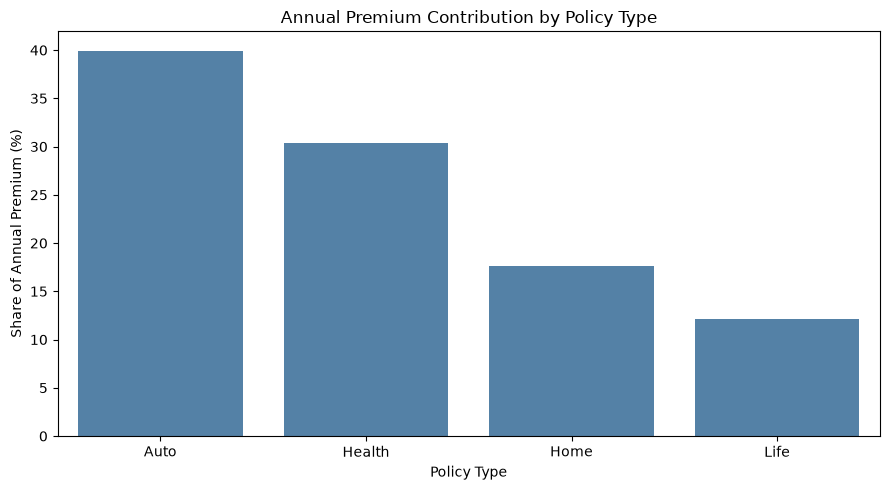

In [7]:

# BR 2 — Annual Premium Contribution by Policy Type

plt.figure(figsize=(9, 5))

sns.barplot(
    data=premium_analysis,
    x="Policy_Type",
    y="Premium_Share_Pct",
    color="steelblue"
)

plt.title("Annual Premium Contribution by Policy Type")
plt.xlabel("Policy Type")
plt.ylabel("Share of Annual Premium (%)")

plt.tight_layout()
plt.show()



### Key Finding — Annual Premium Contribution

Auto insurance contributes the largest share of total
annualized premiums (39.95%), followed by Health (30.33%).

Life insurance has the highest average annual premium
(₹22,443.89), despite representing the smallest policy
segment.

Overall, premium contribution is driven mainly by policy
volume rather than substantial differences in average
annual premiums.

**Note:** Annualized premium amounts do not represent
verified premium collections or recognized revenue.


In [8]:

# BR 3 — Coverage Exposure by Policy Type

coverage_analysis = (
    policies.groupby("Policy_Type")
    .agg(
        Total_Policies=("Policy_ID", "count"),
        Total_Coverage=("Coverage_Amount", "sum"),
        Average_Coverage=("Coverage_Amount", "mean"),
        Median_Coverage=("Coverage_Amount", "median")
    )
    .reset_index()
)

# Calculate coverage contribution
coverage_analysis["Coverage_Share_Pct"] = (
    coverage_analysis["Total_Coverage"]
    / coverage_analysis["Total_Coverage"].sum() * 100
)

# Sort by total coverage
coverage_analysis = coverage_analysis.sort_values(
    "Total_Coverage", ascending=False
)

display(coverage_analysis.round(2))

print(
    "Total Portfolio Coverage:",
    round(coverage_analysis["Total_Coverage"].sum(), 2)
)

print(
    "Total Coverage Share:",
    round(coverage_analysis["Coverage_Share_Pct"].sum(), 2)
)


,Policy_Type,Total_Policies,Total_Coverage,Average_Coverage,Median_Coverage,Coverage_Share_Pct
0,Auto,5953,"4,451,725,574.93","747,812.12","554,870.49",39.95
1,Health,4560,"3,408,095,265.44","747,389.31","574,065.54",30.58
2,Home,2691,"1,956,517,310.11","727,059.57","541,504.87",17.56
3,Life,1796,"1,326,878,617.34","738,796.56","551,564.66",11.91


Total Portfolio Coverage: 11143216767.82
Total Coverage Share: 100.0


In [9]:

# BR 4 — Premium-to-Coverage Ratio by Policy Type

premium_coverage = (
    policies.groupby("Policy_Type")
    .agg(
        Total_Policies=("Policy_ID", "count"),
        Total_Annual_Premium=("Annual_Premium", "sum"),
        Total_Coverage=("Coverage_Amount", "sum")
    )
    .reset_index()
)

# Calculate premium-to-coverage ratio
premium_coverage["Premium_to_Coverage_Pct"] = (
    premium_coverage["Total_Annual_Premium"]
    / premium_coverage["Total_Coverage"] * 100
)

# Sort by ratio
premium_coverage = premium_coverage.sort_values(
    "Premium_to_Coverage_Pct", ascending=False
)

display(premium_coverage.round(2))

print(
    "Overall Premium-to-Coverage Ratio (%):",
    round(
        policies["Annual_Premium"].sum()
        / policies["Coverage_Amount"].sum() * 100,
        2
    )
)


,Policy_Type,Total_Policies,Total_Annual_Premium,Total_Coverage,Premium_to_Coverage_Pct
3,Life,1796,"40,309,218.01","1,326,878,617.34",3.04
2,Home,2691,"58,500,118.75","1,956,517,310.11",2.99
0,Auto,5953,"132,829,680.77","4,451,725,574.93",2.98
1,Health,4560,"100,863,927.04","3,408,095,265.44",2.96


Overall Premium-to-Coverage Ratio (%): 2.98


In [10]:

# BR 5 — Policy Status and Annual Premium Exposure

policy_status_analysis = (
    policies.groupby("Policy_Status")
    .agg(
        Total_Policies=("Policy_ID", "count"),
        Total_Annual_Premium=("Annual_Premium", "sum"),
        Average_Annual_Premium=("Annual_Premium", "mean")
    )
    .reset_index()
)

# Calculate policy share
policy_status_analysis["Policy_Share_Pct"] = (
    policy_status_analysis["Total_Policies"]
    / policy_status_analysis["Total_Policies"].sum() * 100
)

# Calculate annual premium share
policy_status_analysis["Premium_Share_Pct"] = (
    policy_status_analysis["Total_Annual_Premium"]
    / policy_status_analysis["Total_Annual_Premium"].sum() * 100
)

policy_status_analysis = policy_status_analysis.sort_values(
    "Total_Policies", ascending=False
)

display(policy_status_analysis.round(2))

print("Total Policies:",
      policy_status_analysis["Total_Policies"].sum())

print("Total Premium Share (%):",
      round(policy_status_analysis["Premium_Share_Pct"].sum(), 2))


,Policy_Status,Total_Policies,Total_Annual_Premium,Average_Annual_Premium,Policy_Share_Pct,Premium_Share_Pct
0,Active,8292,"183,601,121.73","22,141.96",55.28,55.22
2,Expired,5218,"116,158,592.28","22,261.13",34.79,34.93
1,Cancelled,1490,"32,743,230.56","21,975.32",9.93,9.85


Total Policies: 15000
Total Premium Share (%): 100.0


In [11]:

# BR 6 — Annual Premium Distribution and Outliers

premium_summary = policies["Annual_Premium"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
)

q1 = policies["Annual_Premium"].quantile(0.25)
q3 = policies["Annual_Premium"].quantile(0.75)

iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

high_premium_policies = policies[
    policies["Annual_Premium"] > upper_limit
]

display(premium_summary.round(2))

print("IQR:", round(iqr, 2))
print("Upper Outlier Limit:", round(upper_limit, 2))
print("High-Premium Outliers:", len(high_premium_policies))
print(
    "Outlier Percentage:",
    round(len(high_premium_policies) / len(policies) * 100, 2)
)


count    15,000.00
mean     22,166.86
std      16,306.42
min       1,501.82
25%      11,486.78
50%      17,778.82
75%      27,801.88
90%      41,611.81
95%      52,831.41
max     222,852.66
Name: Annual_Premium, dtype: float64

IQR: 16315.1
Upper Outlier Limit: 52274.52
High-Premium Outliers: 774
Outlier Percentage: 5.16


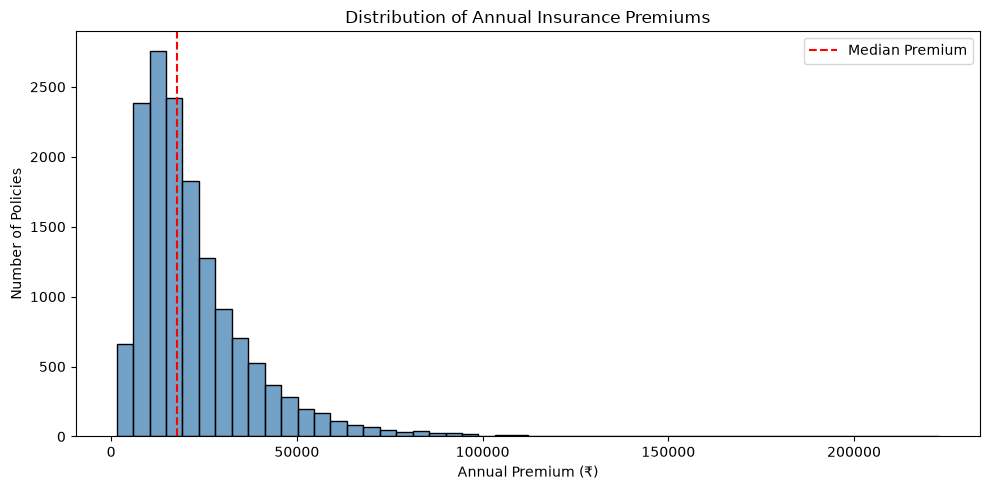

In [12]:

# BR 6 — Annual Premium Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=policies,
    x="Annual_Premium",
    bins=50,
    color="steelblue"
)

plt.axvline(
    policies["Annual_Premium"].median(),
    color="red",
    linestyle="--",
    label="Median Premium"
)

plt.title("Distribution of Annual Insurance Premiums")
plt.xlabel("Annual Premium (₹)")
plt.ylabel("Number of Policies")
plt.legend()

plt.tight_layout()
plt.show()


In [13]:

# BR 7 — Coverage and Annual Premium Correlation

correlation_results = pd.DataFrame({
    "Method": ["Pearson", "Spearman"],
    "Correlation": [
        policies["Coverage_Amount"].corr(
            policies["Annual_Premium"], method="pearson"
        ),
        policies["Coverage_Amount"].corr(
            policies["Annual_Premium"], method="spearman"
        )
    ]
})

display(correlation_results.round(4))


,Method,Correlation
0,Pearson,0.85
1,Spearman,0.83


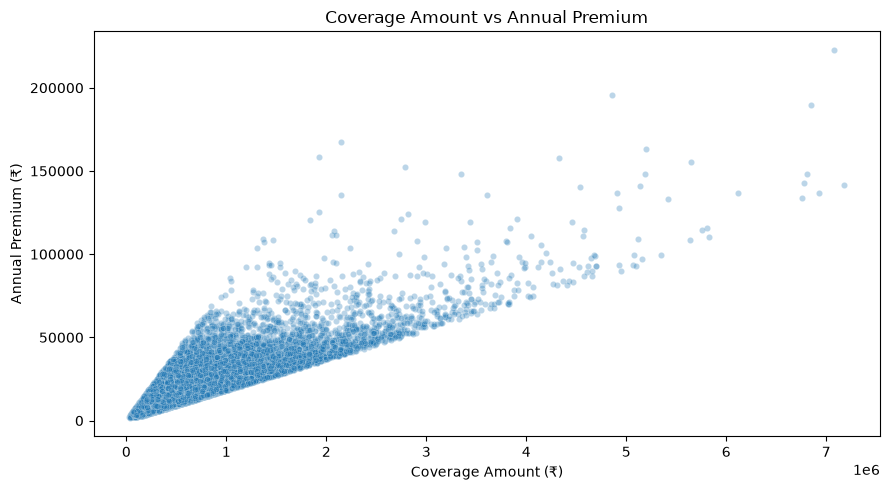

In [14]:

# BR 7 — Coverage vs Annual Premium

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=policies,
    x="Coverage_Amount",
    y="Annual_Premium",
    alpha=0.3,
    s=20
)

plt.title("Coverage Amount vs Annual Premium")
plt.xlabel("Coverage Amount (₹)")
plt.ylabel("Annual Premium (₹)")

plt.tight_layout()
plt.show()



### Key Finding — Coverage and Premium Relationship

Coverage amount and annual premium show a strong
positive relationship, with Pearson correlation of
0.85 and Spearman correlation of 0.83.

This indicates that higher coverage amounts are
generally associated with higher annual premiums.

The relationship supports coverage amount as an
important factor for premium analysis, although
correlation does not establish causation.


In [15]:

# BR 8 — Claims-to-Premium Ratio by Policy Type

# Calculate total claim amount for each policy
policy_claims = (
    claims.groupby("Policy_ID")
    .agg(Total_Claim_Amount=("Claim_Amount", "sum"))
    .reset_index()
)

# Merge claims with policy details
policy_financial = policies.merge(
    policy_claims,
    on="Policy_ID",
    how="left",
    validate="one_to_one"
)

# Policies without claims have zero claimed amount
policy_financial["Total_Claim_Amount"] = (
    policy_financial["Total_Claim_Amount"].fillna(0)
)

# Aggregate by policy type
claims_premium_analysis = (
    policy_financial.groupby("Policy_Type")
    .agg(
        Total_Policies=("Policy_ID", "count"),
        Total_Annual_Premium=("Annual_Premium", "sum"),
        Total_Claim_Amount=("Total_Claim_Amount", "sum")
    )
    .reset_index()
)

# Calculate claims-to-premium ratio
claims_premium_analysis["Claims_to_Premium_Pct"] = (
    claims_premium_analysis["Total_Claim_Amount"]
    / claims_premium_analysis["Total_Annual_Premium"] * 100
)

claims_premium_analysis = claims_premium_analysis.sort_values(
    "Claims_to_Premium_Pct", ascending=False
)

display(claims_premium_analysis.round(2))


,Policy_Type,Total_Policies,Total_Annual_Premium,Total_Claim_Amount,Claims_to_Premium_Pct
1,Health,4560,"100,863,927.04","330,127,253.85",327.30
2,Home,2691,"58,500,118.75","187,122,148.12",319.87
0,Auto,5953,"132,829,680.77","417,466,453.92",314.29
3,Life,1796,"40,309,218.01","118,933,745.56",295.05


In [16]:

# BR 9 — Claim Payment Performance by Policy Type

# Aggregate payments at claim level
claim_payments = (
    payments.groupby("Claim_ID")
    .agg(
        Total_Payment_Amount=("Payment_Amount", "sum")
    )
    .reset_index()
)

# Join claims with policy type and payments
claims_payment_data = (
    claims.merge(
        policies[["Policy_ID", "Policy_Type"]],
        on="Policy_ID",
        how="left",
        validate="many_to_one"
    )
    .merge(
        claim_payments,
        on="Claim_ID",
        how="left",
        validate="one_to_one"
    )
)

# Claims without payment records
claims_payment_data["Total_Payment_Amount"] = (
    claims_payment_data["Total_Payment_Amount"].fillna(0)
)

# Summarize financial amounts by policy type
payment_performance = (
    claims_payment_data.groupby("Policy_Type")
    .agg(
        Total_Claims=("Claim_ID", "count"),
        Total_Claim_Amount=("Claim_Amount", "sum"),
        Total_Payment_Amount=("Total_Payment_Amount", "sum")
    )
    .reset_index()
)

# Calculate payment-to-claim ratio
payment_performance["Payment_to_Claim_Pct"] = (
    payment_performance["Total_Payment_Amount"]
    / payment_performance["Total_Claim_Amount"] * 100
)

payment_performance = payment_performance.sort_values(
    "Payment_to_Claim_Pct", ascending=False
)

display(payment_performance.round(2))

print(
    "Total Recorded Payments:",
    round(payment_performance["Total_Payment_Amount"].sum(), 2)
)


,Policy_Type,Total_Claims,Total_Claim_Amount,Total_Payment_Amount,Payment_to_Claim_Pct
1,Health,7784,"330,127,253.85","161,214,045.16",48.83
2,Home,4458,"187,122,148.12","89,843,226.21",48.01
0,Auto,9832,"417,466,453.92","198,733,114.68",47.60
3,Life,2926,"118,933,745.56","56,485,859.72",47.49


Total Recorded Payments: 506276245.77


In [17]:

# BR 10 — Payment Coverage by Claim Status

payment_status_analysis = (
    claims_payment_data.groupby("Claim_Status")
    .agg(
        Total_Claims=("Claim_ID", "count"),
        Total_Claim_Amount=("Claim_Amount", "sum"),
        Total_Payment_Amount=("Total_Payment_Amount", "sum"),
        Claims_With_Payments=(
            "Total_Payment_Amount",
            lambda x: (x > 0).sum()
        )
    )
    .reset_index()
)

# Percentage of claims with recorded payments
payment_status_analysis["Claims_With_Payments_Pct"] = (
    payment_status_analysis["Claims_With_Payments"]
    / payment_status_analysis["Total_Claims"] * 100
)

# Payment amount relative to claimed amount
payment_status_analysis["Payment_to_Claim_Pct"] = (
    payment_status_analysis["Total_Payment_Amount"]
    / payment_status_analysis["Total_Claim_Amount"] * 100
)

display(
    payment_status_analysis.sort_values(
        "Total_Claims", ascending=False
    ).round(2)
)

print(
    "Total Claims:",
    payment_status_analysis["Total_Claims"].sum()
)

print(
    "Total Payments:",
    round(payment_status_analysis["Total_Payment_Amount"].sum(), 2)
)


,Claim_Status,Total_Claims,Total_Claim_Amount,Total_Payment_Amount,Claims_With_Payments,Claims_With_Payments_Pct,Payment_to_Claim_Pct
3,Settled,10569,"447,708,778.85","323,529,209.64",9837,93.07,72.26
0,Approved,6100,"252,459,288.83","182,747,036.13",5704,93.51,72.39
2,Rejected,4256,"182,086,789.11",0.00,0,0.00,0.00
1,Pending,4075,"171,394,744.66",0.00,0,0.00,0.00


Total Claims: 25000
Total Payments: 506276245.77


In [18]:

# BR 11 — Unpaid Claim Amount Difference

# Focus on Approved and Settled claims
eligible_claims = claims_payment_data[
    claims_payment_data["Claim_Status"].isin(["Approved", "Settled"])
].copy()

# Calculate claim amount not covered by recorded payments
eligible_claims["Unpaid_Amount_Difference"] = (
    eligible_claims["Claim_Amount"]
    - eligible_claims["Total_Payment_Amount"]
)

# Summarize by claim status
unpaid_analysis = (
    eligible_claims.groupby("Claim_Status")
    .agg(
        Total_Claims=("Claim_ID", "count"),
        Total_Claim_Amount=("Claim_Amount", "sum"),
        Total_Payment_Amount=("Total_Payment_Amount", "sum"),
        Unpaid_Amount_Difference=("Unpaid_Amount_Difference", "sum")
    )
    .reset_index()
)

# Calculate unpaid difference percentage
unpaid_analysis["Unpaid_Difference_Pct"] = (
    unpaid_analysis["Unpaid_Amount_Difference"]
    / unpaid_analysis["Total_Claim_Amount"] * 100
)

display(unpaid_analysis.round(2))

print(
    "Total Unpaid Claim Amount Difference:",
    round(unpaid_analysis["Unpaid_Amount_Difference"].sum(), 2)
)


,Claim_Status,Total_Claims,Total_Claim_Amount,Total_Payment_Amount,Unpaid_Amount_Difference,Unpaid_Difference_Pct
0,Approved,6100,"252,459,288.83","182,747,036.13","69,712,252.70",27.61
1,Settled,10569,"447,708,778.85","323,529,209.64","124,179,569.21",27.74


Total Unpaid Claim Amount Difference: 193891821.91


In [19]:

# BR 12 — Regional Financial Exposure

# Join policies with customer regions
regional_policies = policies.merge(
    customers[["Customer_ID", "Region"]],
    on="Customer_ID",
    how="left",
    validate="many_to_one"
)

# Summarize financial exposure by region
regional_financial = (
    regional_policies.groupby("Region")
    .agg(
        Total_Policies=("Policy_ID", "count"),
        Total_Annual_Premium=("Annual_Premium", "sum"),
        Total_Coverage=("Coverage_Amount", "sum")
    )
    .reset_index()
)

# Calculate annual premium contribution
regional_financial["Premium_Share_Pct"] = (
    regional_financial["Total_Annual_Premium"]
    / regional_financial["Total_Annual_Premium"].sum() * 100
)

# Calculate premium-to-coverage ratio
regional_financial["Premium_to_Coverage_Pct"] = (
    regional_financial["Total_Annual_Premium"]
    / regional_financial["Total_Coverage"] * 100
)

regional_financial = regional_financial.sort_values(
    "Total_Annual_Premium", ascending=False
)

display(regional_financial.round(2))

print("Total Policies:", regional_financial["Total_Policies"].sum())
print(
    "Total Premium Share (%):",
    round(regional_financial["Premium_Share_Pct"].sum(), 2)
)


,Region,Total_Policies,Total_Annual_Premium,Total_Coverage,Premium_Share_Pct,Premium_to_Coverage_Pct
4,West,3048,"67,541,005.56","2,238,713,744.36",20.31,3.02
0,Central,3006,"67,467,790.55","2,287,819,620.47",20.29,2.95
1,East,2994,"66,004,876.90","2,198,169,182.80",19.85,3.00
2,North,3019,"65,925,776.66","2,199,467,764.13",19.83,3.00
3,South,2933,"65,563,494.90","2,219,046,456.06",19.72,2.95


Total Policies: 15000
Total Premium Share (%): 100.0


In [20]:

# BR 13 — Annual Premium Concentration

# Sort policies by annual premium
premium_ranked = policies.sort_values(
    "Annual_Premium", ascending=False
).copy()

# Calculate top 10% policy count
top_10_count = int(len(premium_ranked) * 0.10)

# Select top 10% highest-premium policies
top_10_policies = premium_ranked.head(top_10_count)

# Calculate their premium contribution
top_10_premium = top_10_policies["Annual_Premium"].sum()
total_premium = policies["Annual_Premium"].sum()

top_10_share = top_10_premium / total_premium * 100

print("Total Policies:", len(policies))
print("Top 10% Policies:", top_10_count)
print("Top 10% Annual Premium:", round(top_10_premium, 2))
print("Total Annual Premium:", round(total_premium, 2))
print("Top 10% Premium Contribution (%):", round(top_10_share, 2))


Total Policies: 15000
Top 10% Policies: 1500
Top 10% Annual Premium: 88779347.89
Total Annual Premium: 332502944.57
Top 10% Premium Contribution (%): 26.7


In [21]:

# BR 14 — Policy Age and Annual Premium Analysis

analysis_date = pd.Timestamp("2026-09-30")

policy_age = policies.copy()

policy_age["Start_Date"] = pd.to_datetime(
    policy_age["Start_Date"]
)

# Calculate elapsed policy age in days
policy_age["Policy_Age_Days"] = (
    analysis_date - policy_age["Start_Date"]
).dt.days

# Categorize policy age
policy_age["Policy_Age_Group"] = pd.cut(
    policy_age["Policy_Age_Days"],
    bins=[-float("inf"), 365, 730, 1095, float("inf")],
    labels=["0-1 Year", "1-2 Years", "2-3 Years", "3+ Years"]
)

# Exclude future-start policies from age comparison
policy_age_valid = policy_age[
    policy_age["Policy_Age_Days"] >= 0
]

policy_age_analysis = (
    policy_age_valid.groupby(
        "Policy_Age_Group", observed=True
    )
    .agg(
        Total_Policies=("Policy_ID", "count"),
        Average_Annual_Premium=("Annual_Premium", "mean"),
        Median_Annual_Premium=("Annual_Premium", "median")
    )
    .reset_index()
)

display(policy_age_analysis.round(2))

print(
    "Future-Start Policies Excluded:",
    (policy_age["Policy_Age_Days"] < 0).sum()
)


,Policy_Age_Group,Total_Policies,Average_Annual_Premium,Median_Annual_Premium
0,0-1 Year,629,"21,579.89","17,299.92"
1,1-2 Years,2473,"22,406.40","17,875.75"
2,2-3 Years,2467,"21,666.70","17,327.13"
3,3+ Years,9431,"22,274.04","17,877.93"


Future-Start Policies Excluded: 0


In [22]:

# BR 15 — Coverage Exposure by Policy Status

status_coverage = (
    policies.groupby("Policy_Status")
    .agg(
        Total_Policies=("Policy_ID", "count"),
        Total_Annual_Premium=("Annual_Premium", "sum"),
        Total_Coverage=("Coverage_Amount", "sum"),
        Average_Coverage=("Coverage_Amount", "mean")
    )
    .reset_index()
)

# Coverage contribution by status
status_coverage["Coverage_Share_Pct"] = (
    status_coverage["Total_Coverage"]
    / status_coverage["Total_Coverage"].sum() * 100
)

# Premium relative to coverage
status_coverage["Premium_to_Coverage_Pct"] = (
    status_coverage["Total_Annual_Premium"]
    / status_coverage["Total_Coverage"] * 100
)

display(
    status_coverage.sort_values(
        "Total_Coverage", ascending=False
    ).round(2)
)

print("Total Policies:", status_coverage["Total_Policies"].sum())
print(
    "Total Coverage Share (%):",
    round(status_coverage["Coverage_Share_Pct"].sum(), 2)
)


,Policy_Status,Total_Policies,Total_Annual_Premium,Total_Coverage,Average_Coverage,Coverage_Share_Pct,Premium_to_Coverage_Pct
0,Active,8292,"183,601,121.73","6,163,185,912.99","743,268.92",55.31,2.98
2,Expired,5218,"116,158,592.28","3,912,049,031.10","749,721.93",35.11,2.97
1,Cancelled,1490,"32,743,230.56","1,067,981,823.73","716,766.32",9.58,3.07


Total Policies: 15000
Total Coverage Share (%): 100.0


In [23]:

# BR 16 — Policy-Level Claims Exposure

# Identify policies with at least one claim
policy_financial["Has_Claim"] = (
    policy_financial["Total_Claim_Amount"] > 0
)

# Analyze claim incidence by policy type
policy_claim_incidence = (
    policy_financial.groupby("Policy_Type")
    .agg(
        Total_Policies=("Policy_ID", "count"),
        Policies_With_Claims=("Has_Claim", "sum")
    )
    .reset_index()
)

# Calculate policy-level claim incidence
policy_claim_incidence["Claim_Incidence_Pct"] = (
    policy_claim_incidence["Policies_With_Claims"]
    / policy_claim_incidence["Total_Policies"] * 100
)

policy_claim_incidence = policy_claim_incidence.sort_values(
    "Claim_Incidence_Pct", ascending=False
)

display(policy_claim_incidence.round(2))

print(
    "Total Policies With Claims:",
    policy_claim_incidence["Policies_With_Claims"].sum()
)

print(
    "Overall Claim Incidence (%):",
    round(
        policy_claim_incidence["Policies_With_Claims"].sum()
        / len(policy_financial) * 100,
        2
    )
)


,Policy_Type,Total_Policies,Policies_With_Claims,Claim_Incidence_Pct
1,Health,4560,3773,82.74
2,Home,2691,2189,81.35
3,Life,1796,1449,80.68
0,Auto,5953,4769,80.11


Total Policies With Claims: 12180
Overall Claim Incidence (%): 81.2


In [24]:

# BR 17 — Claim Frequency per Policy

# Count claims for each policy
claim_counts = (
    claims.groupby("Policy_ID")
    .agg(Claim_Count=("Claim_ID", "count"))
    .reset_index()
)

# Include policies without claims
policy_frequency = policies[
    ["Policy_ID", "Policy_Type"]
].merge(
    claim_counts,
    on="Policy_ID",
    how="left",
    validate="one_to_one"
)

policy_frequency["Claim_Count"] = (
    policy_frequency["Claim_Count"].fillna(0).astype(int)
)

# Summarize by policy type
claim_frequency_analysis = (
    policy_frequency.groupby("Policy_Type")
    .agg(
        Total_Policies=("Policy_ID", "count"),
        Total_Claims=("Claim_Count", "sum"),
        Average_Claims_Per_Policy=("Claim_Count", "mean"),
        Max_Claims_Per_Policy=("Claim_Count", "max")
    )
    .reset_index()
)

display(
    claim_frequency_analysis.sort_values(
        "Average_Claims_Per_Policy",
        ascending=False
    ).round(2)
)

print("Total Policies:", len(policy_frequency))
print("Total Claims:", policy_frequency["Claim_Count"].sum())


,Policy_Type,Total_Policies,Total_Claims,Average_Claims_Per_Policy,Max_Claims_Per_Policy
1,Health,4560,7784,1.71,8
2,Home,2691,4458,1.66,8
0,Auto,5953,9832,1.65,8
3,Life,1796,2926,1.63,9


Total Policies: 15000
Total Claims: 25000


In [25]:

# BR 18 — Premium Bands and Claim Incidence

premium_claims = policy_financial.copy()

# Divide policies into four equal-sized premium groups
premium_claims["Premium_Band"] = pd.qcut(
    premium_claims["Annual_Premium"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"]
)

# Identify policies with recorded claims
premium_claims["Has_Claim"] = (
    premium_claims["Total_Claim_Amount"] > 0
)

# Analyze claim incidence by premium band
premium_band_analysis = (
    premium_claims.groupby("Premium_Band", observed=True)
    .agg(
        Total_Policies=("Policy_ID", "count"),
        Average_Annual_Premium=("Annual_Premium", "mean"),
        Policies_With_Claims=("Has_Claim", "sum")
    )
    .reset_index()
)

premium_band_analysis["Claim_Incidence_Pct"] = (
    premium_band_analysis["Policies_With_Claims"]
    / premium_band_analysis["Total_Policies"] * 100
)

display(premium_band_analysis.round(2))

print("Total Policies:", premium_band_analysis["Total_Policies"].sum())
print(
    "Overall Claim Incidence (%):",
    round(
        premium_band_analysis["Policies_With_Claims"].sum()
        / premium_band_analysis["Total_Policies"].sum() * 100,
        2
    )
)


,Premium_Band,Total_Policies,Average_Annual_Premium,Policies_With_Claims,Claim_Incidence_Pct
0,Low,3750,"8,151.30",3062,81.65
1,Lower-Middle,3750,"14,514.38",3046,81.23
2,Upper-Middle,3750,"22,146.14",3043,81.15
3,High,3750,"43,855.64",3029,80.77


Total Policies: 15000
Overall Claim Incidence (%): 81.2



## Key Findings & Business Recommendations

### Key Findings

1. **Portfolio Composition:** The portfolio contains 15,000 policies, with Auto (39.69%) and Health (30.40%) representing the largest segments.

2. **Annualized Premiums:** Total annualized premiums amount to ₹33.25 Cr. Auto contributes the highest share (39.95%).

3. **Coverage Exposure:** Total recorded policy coverage is ₹1,114.32 Cr, with an overall premium-to-coverage ratio of 2.98%. Coverage represents policy limits, not expected losses.

4. **Premium Distribution:** Annual premiums are right-skewed, with a median of ₹17,778.82 and 5.16% of policies above the IQR outlier threshold.

5. **Premium–Coverage Relationship:** Premiums and coverage amounts show a strong positive association (Pearson correlation: 0.85).

6. **Claims and Payments:** Recorded claims total ₹105.36 Cr, compared with ₹50.63 Cr in recorded payments. The overall payment-to-claim amount ratio is approximately 48.05%. These figures cover the available historical records and do not represent an actuarial loss ratio.

7. **Payment Differences:** Approved and Settled claims have a combined claim-minus-payment difference of ₹19.39 Cr. This is not necessarily an outstanding payable balance.

8. **Regional Performance:** Annualized premium contributions are relatively balanced across five regions, ranging from 19.72% to 20.31%.

9. **Premium Concentration:** The highest-premium 10% of policies contribute 26.70% of total annualized premiums.

10. **Policy Age:** Average annual premiums vary only modestly across policy-age groups, with no clear increasing or decreasing pattern.

11. **Policy Status:** Active-labeled policies account for 55.31% of total recorded coverage. Status-date inconsistencies limit interpretation of current exposure.

12. **Claim Incidence:** 81.20% of policies have at least one historical claim. Health policies have the highest incidence (82.74%).

13. **Claim Frequency:** Health policies average 1.71 recorded claims per policy, compared with 1.63–1.66 across the other policy types.

14. **Premium Segmentation:** Claim incidence ranges from 81.65% in the lowest premium quartile to 80.77% in the highest, indicating only a small descriptive difference.

### Business Recommendations

1. **Monitor Portfolio Concentration:** Track premium and coverage exposure by policy type, region, and premium band.

2. **Investigate Payment Differences:** Reconcile claim amounts, approved payable amounts, and recorded payments before identifying outstanding obligations.

3. **Strengthen Policy Data Quality:** Resolve inconsistencies between recorded policy statuses and effective dates before calculating active exposure.

4. **Review Claim Activity:** Monitor claim incidence and frequency by policy type while accounting for policy duration and exposure periods.

5. **Improve Financial Reporting:** Separate annualized policy premiums from actual premium collections, and distinguish recorded claim amounts from approved liabilities and payments.

### Analysis Limitations

- Annualized premiums are not verified premium collections or recognized revenue.
- Claims and payments cover multiple years and are not matched to earned premiums for an equivalent period.
- Recorded coverage amounts represent policy limits, not expected claim liabilities.
- Policy status labels contain date inconsistencies.
- Claim incidence and frequency are historical, not annualized or exposure-adjusted.
- Descriptive relationships do not establish causation.

### Conclusion

The portfolio shows balanced regional premium contributions, a strong premium–coverage relationship, and relatively similar historical claim incidence across policy types and premium bands. The analysis highlights opportunities to improve financial reconciliation, monitor portfolio exposure, and strengthen policy data quality.
